# Ovarian-cancer forecasting tool: usage examples
Synthetic data only (patient SYN38). Time is in months; recurrence intervals are in months
after the end of adjuvant chemotherapy (ACT) unless stated otherwise. The fits here use few
particles to run quickly, so results carry some Monte Carlo noise.

| Section | Contents |
|---|---|
| 0 | Setup; input format: a `PatientRecord` from synthetic data or from your own arrays |
| 1 | Profile: defaults, changing a prior, error messages |
| 2 | Fit at one time point: `fit` → `Snapshot`, report and parameter table |
| 3 | A new reading: `step`, `shrinkage` |
| 4 | Visit-by-visit replay: `replay` → `History`, tables and every figure |
| 5 | Plotting API: options, saving, editing a figure |
| 6 | Options: time decay, censoring, fixed σ, threshold acceptance |
| 7 | MCMC: fit and inspect sampling diagnostics |

## 0 · Setup
Run from the repository root. Loads the synthetic data and the tool.

**Optional MCMC dependencies.** If you want to run Section 7 and PyMC is not installed,
run the next cell once. Restart the kernel afterward, then run the setup cells below.
The other sections do not require these optional dependencies.


In [ ]:
# Uncomment and run once to install the optional MCMC dependencies.
# %pip install -e ".[mcmc]"

In [13]:
%matplotlib inline
from copy import deepcopy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
from IPython.display import display
from ovca import Forecaster, PatientRecord, default_profile, check_profile, ProfileError
from ovca.profile import prior_table

set_matplotlib_formats("png")
plt.rcParams["figure.dpi"] = 80
data = pd.read_csv(Path("data") / "synthetic_data.csv")
record = PatientRecord.from_synthetic(data, "SYN38")
display(record.table())

,month,ca125,phase
0,0.000000,1265.0100,pre
1,2.000000,572.5310,pre
2,3.000000,297.7140,pre
3,5.900000,228.2710,pre
4,6.500000,33.8050,post
5,8.000000,52.3013,post
6,10.000000,64.5305,post
7,11.000000,55.3156,post
8,12.000000,45.5478,post
9,15.133333,112.5840,post


**Input format.** One patient = readings (month, CA-125) + the frontline schedule (start
month of each NACT cycle, month of surgery, start month of each ACT cycle; each cycle is on
for one month by default). For your own data use `PatientRecord.from_arrays`. `t_stop`
(second-line treatment or maintenance starts) and `t_recurrence` (observed recurrence,
absolute month) are optional and are drawn on the figures. The numbers below are made up,
only to show the format.

In [14]:
my_record = PatientRecord.from_arrays(
    "DEMO", t_months=[0, 1, 2, 3.4, 4.5, 5.5, 7, 9, 12],
    ca125=[900, 400, 180, 95, 12, 8, 6, 9, 15],
    nact_starts=[0, 1, 2], t_surgery=4, act_starts=[5, 6, 7],
    t_stop=np.inf, t_recurrence=np.nan)
print(my_record.schedule)
print("end of ACT:", my_record.schedule.t_end)
display(my_record.table())

Schedule(nact_starts=array([0., 1., 2.]), t_surgery=4.0, act_starts=array([5., 6., 7.]), duration=1.0)
end of ACT: 8.0


,month,ca125,phase
0,0.0,900.0,pre
1,1.0,400.0,pre
2,2.0,180.0,pre
3,3.4,95.0,pre
4,4.5,12.0,post
5,5.5,8.0,post
6,7.0,6.0,post
7,9.0,9.0,post
8,12.0,15.0,post


## 1 · Profile and checks
The default profile lists every prior and algorithm setting. The check prints the resolved
priors and marks the ones you changed; a wrong profile gives a message naming the problem.

In [15]:
profile = default_profile()
checked = check_profile(profile)
display(prior_table(checked))

profile: backend = abc, model = growth_death, surgery shifts ['gamma', 'delta'], abc acceptance = likelihood
  parameter                                                  prior  set_by                                                                 meaning
  gamma_pre lognormal(median 0.1, sd_log 0.7); 80%: 0.0408 – 0.245 default                                    model parameter gamma before surgery
  delta_pre   lognormal(median 0.8, sd_log 0.5); 80%: 0.421 – 1.52 default                                    model parameter delta before surgery
shift_gamma            normal(mean 0, sd 0.6); 80%: -0.769 – 0.769 default   surgery effect on gamma: log gamma_post = log gamma_pre + shift_gamma
shift_delta            normal(mean 0, sd 0.6); 80%: -0.769 – 0.769 default   surgery effect on delta: log delta_post = log delta_pre + shift_delta
  level_pre             lognormal(median = that reading, sd_log 1) default                   tumour burden at the first pre-surgery reading (U/mL)
 level_po

,parameter,prior,set_by,meaning
0,gamma_pre,"lognormal(median 0.1, sd_log 0.7); 80%: 0.0408...",default,model parameter gamma before surgery
1,delta_pre,"lognormal(median 0.8, sd_log 0.5); 80%: 0.421 ...",default,model parameter delta before surgery
2,shift_gamma,"normal(mean 0, sd 0.6); 80%: -0.769 – 0.769",default,surgery effect on gamma: log gamma_post = log ...
3,shift_delta,"normal(mean 0, sd 0.6); 80%: -0.769 – 0.769",default,surgery effect on delta: log delta_post = log ...
4,level_pre,"lognormal(median = that reading, sd_log 1)",default,tumour burden at the first pre-surgery reading...
5,level_post,"lognormal(median = that reading, sd_log 1)",default,tumour burden at the first post-surgery readin...
6,sigma,"lognormal(median 0.15, sd_log 0.5); 80%: 0.079...",default,observation error: sd of log CA-125 around the...


In [16]:
profile["priors"]["gamma_pre"] = {"dist": "lognormal", "median": 0.08, "sd_log": 0.7}
# Keep the demonstration quick.
profile["abc"].update(n_particles=300, n_moves=10)
profile["forecast"].update(n_draws=600, step=0.2)
profile = check_profile(profile, verbose=False)
display(prior_table(profile))

wrong = deepcopy(profile)
wrong["priors"]["gamma_pre"] = {"dist": "lognormal", "median": 0.08, "sd_lg": 0.7}
try:
    check_profile(wrong, verbose=False)
except ProfileError as exc:
    print(exc)

,parameter,prior,set_by,meaning
0,gamma_pre,"lognormal(median 0.08, sd_log 0.7); 80%: 0.032...",you,model parameter gamma before surgery
1,delta_pre,"lognormal(median 0.8, sd_log 0.5); 80%: 0.421 ...",default,model parameter delta before surgery
2,shift_gamma,"normal(mean 0, sd 0.6); 80%: -0.769 – 0.769",default,surgery effect on gamma: log gamma_post = log ...
3,shift_delta,"normal(mean 0, sd 0.6); 80%: -0.769 – 0.769",default,surgery effect on delta: log delta_post = log ...
4,level_pre,"lognormal(median = that reading, sd_log 1)",default,tumour burden at the first pre-surgery reading...
5,level_post,"lognormal(median = that reading, sd_log 1)",default,tumour burden at the first post-surgery readin...
6,sigma,"lognormal(median 0.15, sd_log 0.5); 80%: 0.079...",default,observation error: sd of log CA-125 around the...


profile has 2 problem(s):
  - priors.gamma_pre: lognormal takes ['median', 'sd_log'], not 'sd_lg' (did you mean 'sd_log'?)
  - priors.gamma_pre: lognormal needs ['sd_log']


## 2 · Forecast at the end of ACT
Fit with the readings up to the end of ACT only. The report gives the recurrence interval and
the suggested next visit; the summary gives posterior quantiles of every parameter. The black
dashed line in the figure is the synthetic truth, for comparison. Draws that do not recur
within the horizon have recurrence = inf; `report()` caps the interval at horizon + 1.

patient                                                             SYN38
t_now                                                                12.0
n_readings                                                              9
backend                                                               abc
recurrence_low                                                        0.0
recurrence_median                                                     0.0
recurrence_high                                                       0.0
recurrence_level                                                      0.8
recurrence_capped_at                                                 37.0
p_recur_6mo                                                           1.0
p_recur_12mo                                                          1.0
next_visit                                                           18.0
band_at_next_visit      (98.40303417651054, 221.57950488739553, 482.28...
seconds                               

,parameter,q10,q50,q90
0,gamma_pre,0.074092,0.127484,0.230296
1,delta_pre,0.651485,0.809945,0.995715
2,gamma_post,0.143952,0.262388,0.389111
3,delta_post,0.219453,0.400965,0.576659
4,shift_gamma,0.089072,0.660568,1.238228
5,shift_delta,-1.263234,-0.734162,-0.370049
6,level_pre,915.391642,1108.814681,1316.807760
7,level_post,28.645697,36.123677,44.218203
8,ca125_0,915.391642,1108.814681,1316.807760
9,surgery_jump,0.101121,0.146389,0.190527


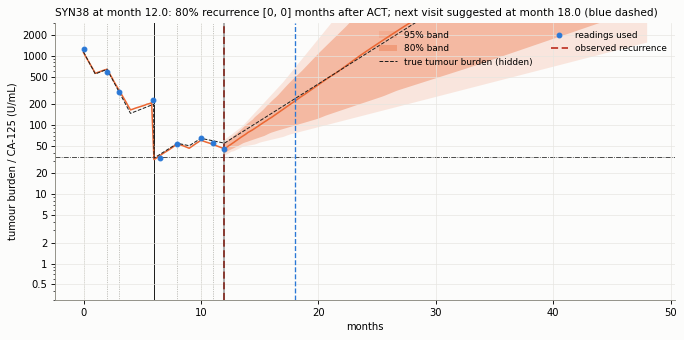

In [17]:
end_act = record.schedule.t_end
observed = record.upto(end_act)
forecaster = Forecaster(profile)
snap = forecaster.fit(observed, t_now=end_act)
# report(): recurrence_low/median/high = 80% interval (months after ACT; capped at horizon + 1),
# p_recur_6mo / 12mo, next_visit (month), band_at_next_visit (tumour 80% band there)
display(pd.Series(snap.report(), name="end of ACT"))
display(snap.summary())
snap.plot()
plt.show()

In [ ]:
# Recurrence time with no forecast horizon: the density runs until 99.9% of the draws have
# recurred, shaded by the 50 / 80 / 95% central intervals (snap.recurrence_times() gives the draws)
snap.plot_recurrence()
plt.show()

In [ ]:
# The same draws as a CDF: P(recurred by each month since diagnosis); grey line = end of ACT
snap.plot_recurrence_cdf()
plt.show()

## 3 · A new reading
Add the next synthetic follow-up reading and refit; compare interval widths and how
surprising the new reading was. Intervals do not always shrink after every reading.

In [18]:
# The snapshot contains only observed visits, so the new visit is added once.
next_index = np.flatnonzero(record.t > end_act)[0]
t_new, y_new = record.t[next_index], record.y[next_index]
updated = forecaster.step(snap, t_new, y_new)
assert updated.previous is snap
display(pd.Series(updated.shrinkage(), name="before vs after"))

t_before                    12.000000
t_after                     15.133333
at                          18.000000
band_ratio_before            4.901152
band_ratio_after             2.046525
recurrence_width_before      0.000000
recurrence_width_after       0.000000
new_reading_month           15.133333
new_reading                112.584000
pit                          0.536667
surprise                     0.926667
Name: before vs after, dtype: float64

## 4 · Visit-by-visit replay
Refit after every visit from the second one on, using only the readings available at that
time, and see how the forecast and the parameter posteriors change.

In [19]:
history = forecaster.replay(record, verbose=False)
assert len(history) == len(record.t) - 1
display(history.table())
display(history.parameter_table().head(12))

,t_now,rec_low,rec_median,rec_high,rec_width,next_visit,seconds,observed_recurrence,observed_in_interval,band_ratio_next,surprise_new_reading
0,2.000000,NaN,NaN,NaN,NaN,NaN,0.016652,0.0,None,2.224823,NaN
1,3.000000,NaN,NaN,NaN,NaN,NaN,0.013958,0.0,None,NaN,0.626667
2,5.900000,NaN,NaN,NaN,NaN,NaN,0.011216,0.0,None,NaN,NaN
3,6.500000,2.207854,19.695529,37.000000,34.792146,12.500000,0.018217,0.0,False,1.809284,NaN
4,8.000000,0.312468,10.205050,37.000000,36.687532,12.400000,0.018823,0.0,False,4.264084,0.336667
5,10.000000,0.000000,0.000000,4.528627,4.528627,12.000000,0.018375,0.0,True,2.337597,0.090000
6,11.000000,0.000000,0.000000,0.000000,0.000000,12.000000,0.020927,0.0,True,1.696443,0.666667
7,12.000000,0.000000,0.000000,0.000000,0.000000,18.000000,0.023094,0.0,True,1.949281,0.820000
8,15.133333,0.000000,0.000000,0.000000,0.000000,21.133333,0.023158,0.0,True,1.483092,0.900000
9,16.133333,0.000000,0.000000,0.000000,0.000000,22.133333,0.026578,0.0,True,NaN,0.863333


,t_now,parameter,q10,q25,q50,q75,q90
0,2.0,gamma_pre,0.030495,0.046874,0.072802,0.113791,0.155559
1,2.0,delta_pre,0.621349,0.750016,0.888265,1.025948,1.205517
2,2.0,gamma_post,NaN,NaN,NaN,NaN,NaN
3,2.0,delta_post,NaN,NaN,NaN,NaN,NaN
4,2.0,shift_gamma,NaN,NaN,NaN,NaN,NaN
5,2.0,shift_delta,NaN,NaN,NaN,NaN,NaN
6,2.0,level_pre,1003.543589,1118.633897,1229.622176,1319.995193,1476.486692
7,2.0,level_post,NaN,NaN,NaN,NaN,NaN
8,2.0,ca125_0,1003.543589,1118.633897,1229.622176,1319.995193,1476.486692
9,2.0,surgery_jump,NaN,NaN,NaN,NaN,NaN


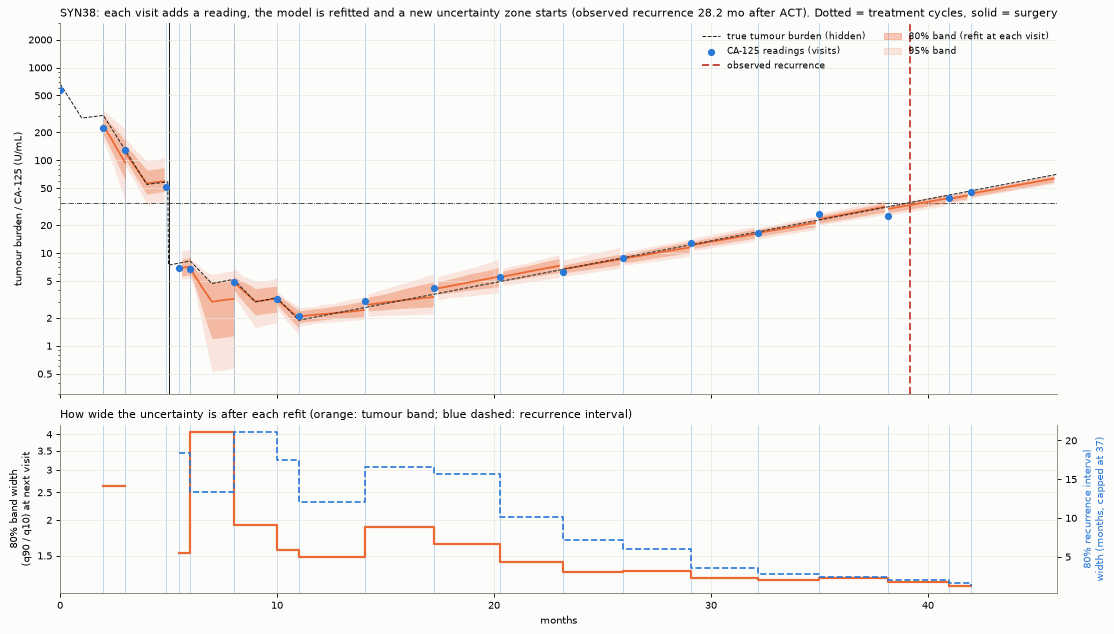

In [8]:
history.plot_tube()
plt.show()

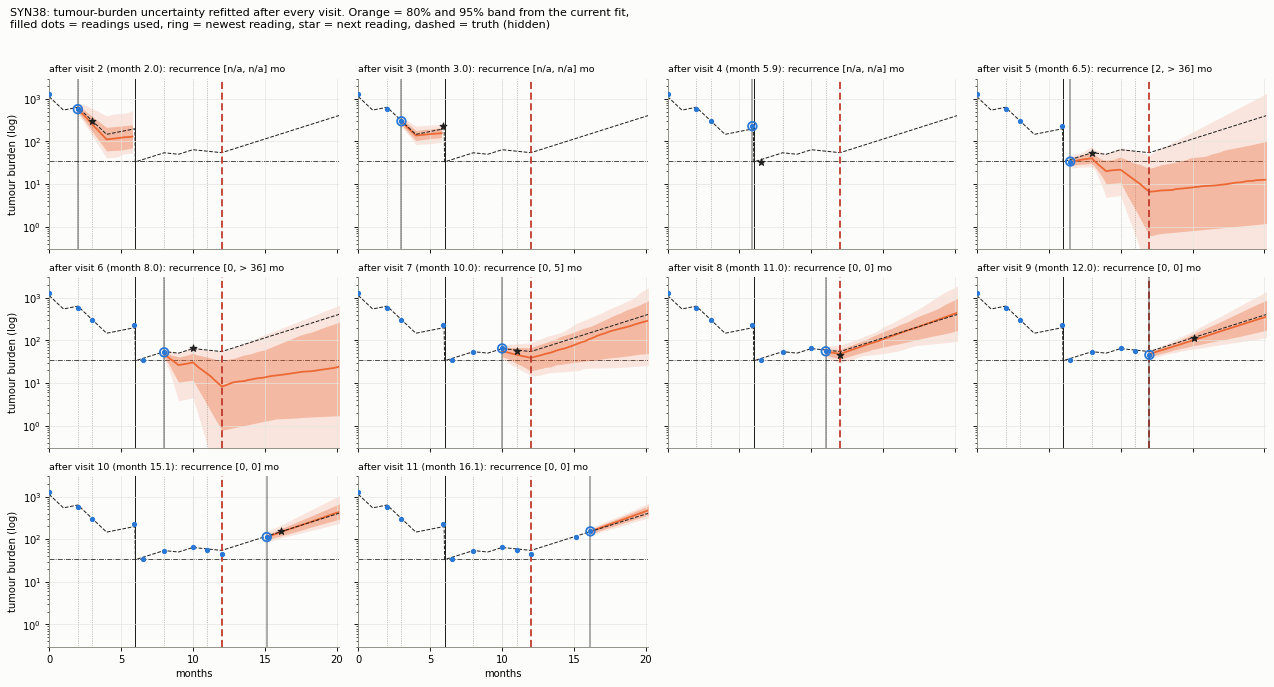

In [8]:
history.plot_panels()
plt.show()

In [ ]:
history.plot_recurrence()
plt.show()

In [ ]:
history.plot_recurrence_cdf()
plt.show()

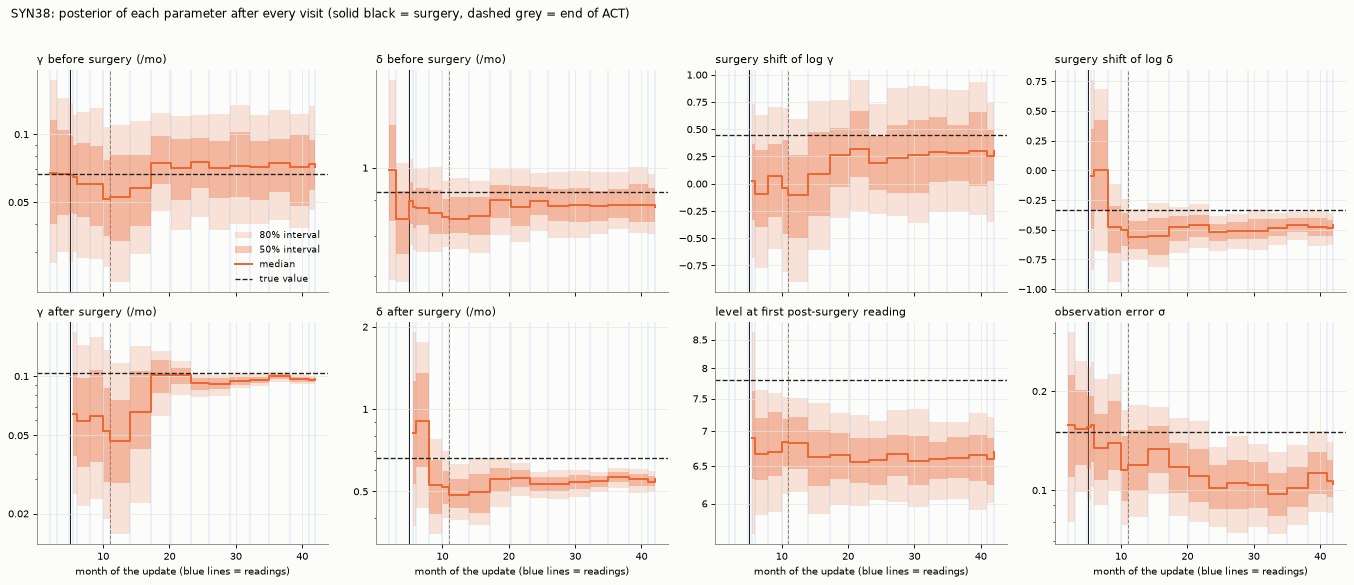

In [10]:
history.plot_parameters()
plt.show()

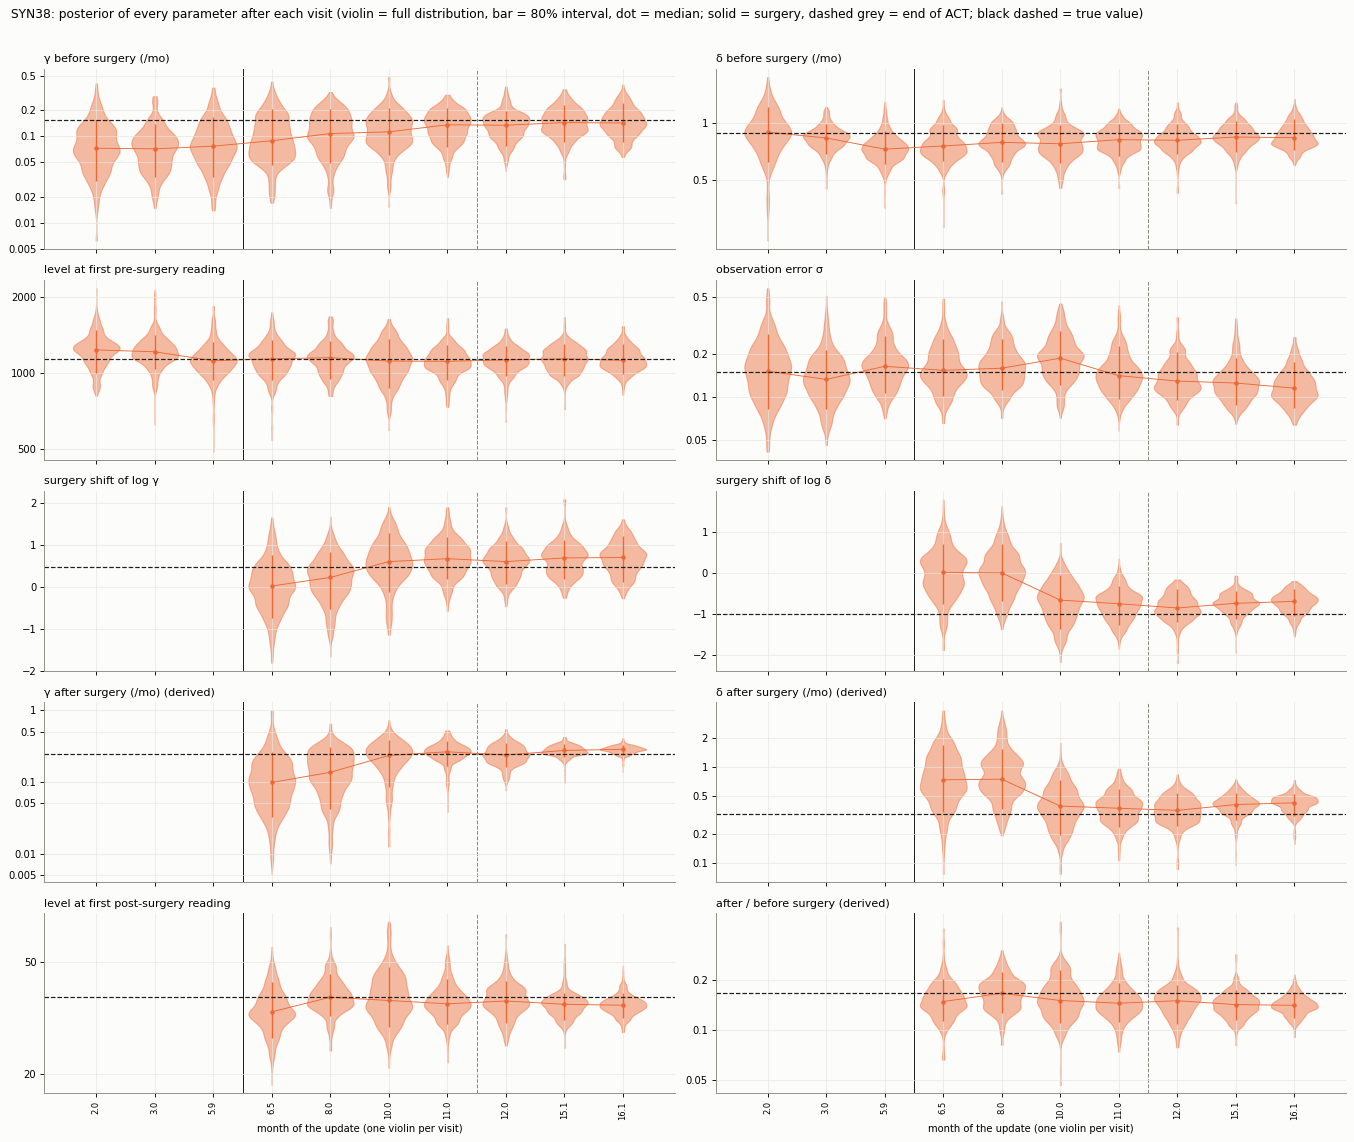

In [9]:
history.plot_parameter_distributions()
plt.show()

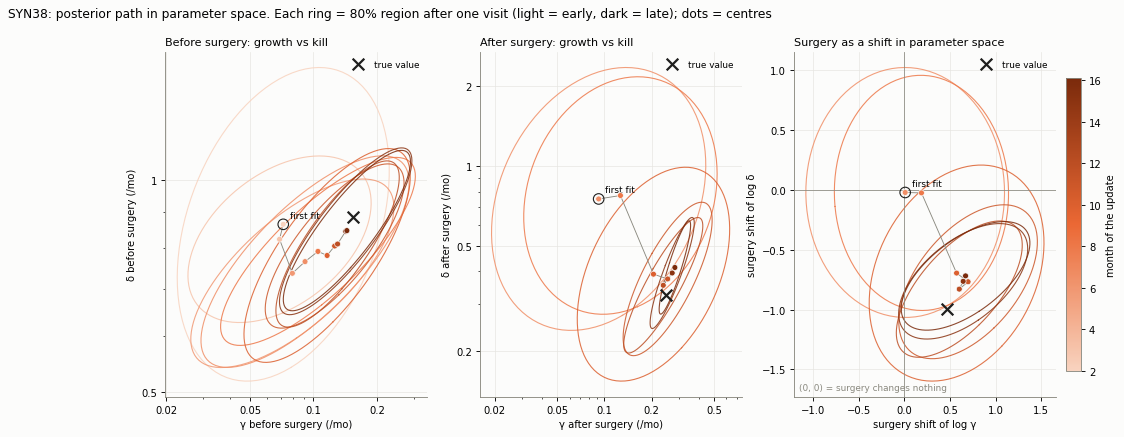

In [10]:
history.plot_parameter_space()
plt.show()

## 5 · Plotting API
Every figure is a method of `History` or `Snapshot`. It returns the matplotlib figure and also
saves it when given a path.

| Method | Figure | Common options |
|---|---|---|
| `hist.plot_tube(path)` | Overview: forecast band per segment + how wide it is | `reference` |
| `hist.plot_panels(path)` | One panel per refit | `reference`, `ncol` |
| `hist.plot_parameters(path)` | Median and 50% / 80% interval of each parameter over time | `params` |
| `hist.plot_parameter_distributions(path)` | Full posterior of each parameter after every visit (violins) | `params`, `n` |
| `hist.plot_parameter_space(path)` | Path in parameter space (80% ellipses) | `pairs` |
| `snap.plot(path)` | Forecast at one time point | `noisy` |
| `snap.plot_recurrence(path)` | Recurrence-time density, no horizon, shaded 50 / 80 / 95% | `until`, `levels` |
| `hist.plot_recurrence(path)` | Recurrence-time density after every refit (ridgeline); `log_x=True` for a log time axis | `until`, `levels`, `log_x`, `xmax` |
| `snap.plot_recurrence_cdf(path)` | P(recurred by t) at one time point | `until` |
| `hist.plot_recurrence_cdf(path)` | P(recurred by t), one panel per refit; `facet=False`: one axis, light = early | `until`, `xmax`, `facet`, `ncol` |

`reference` (black dashed line): `"auto"` (synthetic = truth, real = `"forecast"`),
`"forecast"` (median of the fit to the readings so far), `"hindsight"` (fit once the next
reading is in), `"fit"` (fit to all readings), `"none"`.

['post.png', 'tube.png']


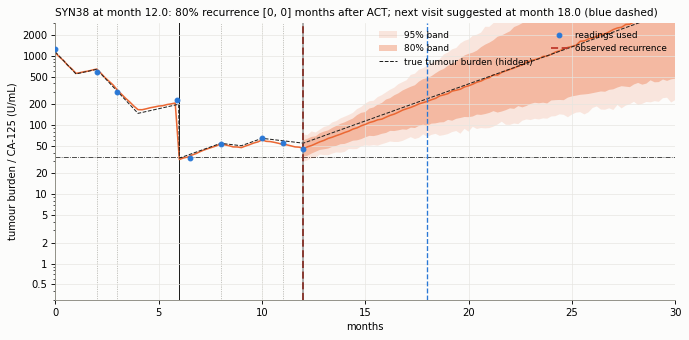

In [11]:
import tempfile
out = Path(tempfile.mkdtemp())
# model fit instead of the truth as the dashed line; only three parameters; save to files
history.plot_tube(out / "tube.png", reference="forecast")
history.plot_parameter_distributions(out / "post.png",
                                     params=["gamma_post", "delta_post", "sigma"])
plt.close("all")
print(sorted(p.name for p in out.iterdir()))

# a figure can be changed afterwards
fig = snap.plot(noisy=True)          # band for the readings (with sigma), not the tumour
fig.axes[0].set_xlim(0, 30)
plt.show()

## 6 · Options
Compared at the same time point (end of ACT): time decay of old readings, readings below 35
treated as censored, fixed observation error, and threshold acceptance (which needs a fixed
sigma). The table gives each fit's 80% recurrence interval and median in months after ACT;
`inf` means beyond that fit's horizon. Small settings, for demonstration only.

In [12]:
variants = {}
decay = deepcopy(profile)
decay["data"]["decay_tau"] = 12.0
variants["time decay (tau = 12 months)"] = decay

censored = deepcopy(profile)
censored["data"]["censor_below"] = 35
variants["censored below 35"] = censored

fixed = deepcopy(profile)
fixed["priors"]["sigma"] = 0.15
variants["fixed sigma = 0.15"] = fixed

threshold = deepcopy(fixed)
threshold["abc"].update(acceptance="threshold", max_generations=8,
                        max_sims_per_gen=6000, batch=600)
variants["threshold acceptance (fixed sigma)"] = threshold

rows = []
for label, option in variants.items():
    option_snap = Forecaster(option).fit(observed, t_now=end_act)
    low, median, high = option_snap.recurrence_interval()
    rows.append({"setting": label, "low (10%)": low, "median": median, "high (90%)": high})
display(pd.DataFrame(rows).set_index("setting").round(2))

,low (10%),median,high (90%)
setting,,,
time decay (tau = 12 months),0.0,0.0,0.00
censored below 35,0.0,0.0,0.00
fixed sigma = 0.15,0.0,0.0,0.00
threshold acceptance (fixed sigma),0.0,0.0,1.03


## 7 · MCMC backend

Use PyMC NUTS for the same single-patient growth–death model, priors, and observation
likelihood as the default likelihood-mode ABC fit. This example reuses the profile and observations above.

The modest settings below are for trying the tool; increase draws, tuning, and chains for
more reliable inference. A replay refits at every visit and can take considerably longer.


Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [prior_z]
Sampling 2 chains for 500 tune and 500 draw iterations (1_000 + 1_000 draws total) took 3 seconds.


patient                                                             SYN38
t_now                                                                12.0
n_readings                                                              9
backend                                                              mcmc
recurrence_low                                                        0.0
recurrence_median                                                     0.0
recurrence_high                                                       0.0
recurrence_level                                                      0.8
recurrence_capped_at                                                 37.0
p_recur_6mo                                                           1.0
p_recur_12mo                                                          1.0
next_visit                                                           18.0
band_at_next_visit      (132.3619451479531, 254.4527399522675, 446.164...
seconds                               

,parameter,q10,q50,q90
0,gamma_pre,0.080768,0.145386,0.248218
1,delta_pre,0.691903,0.841947,1.052633
2,gamma_post,0.177694,0.281240,0.375505
3,delta_post,0.255991,0.424492,0.586336
4,shift_gamma,0.134442,0.618017,1.143358
5,shift_delta,-1.119466,-0.718132,-0.377199
6,level_pre,957.251837,1120.483781,1259.541243
7,level_post,30.135874,35.083734,42.304876
8,ca125_0,957.251837,1120.483781,1259.541243
9,surgery_jump,0.109173,0.140054,0.182977


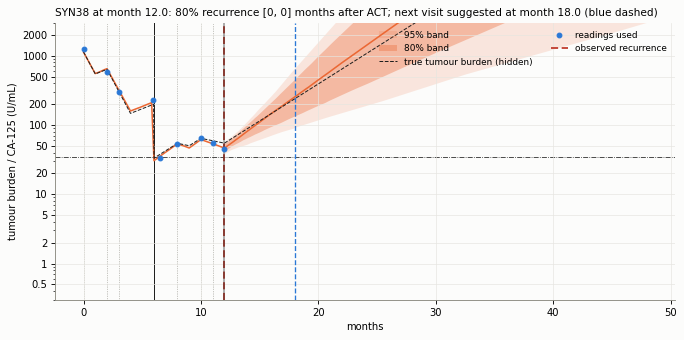

In [25]:
mcmc_profile = deepcopy(profile)
mcmc_profile["backend"] = "mcmc"
# ABC settings are unused by MCMC; reset them to avoid an unused-settings warning.
mcmc_profile["abc"] = default_profile()["abc"]
mcmc_profile["mcmc"].update(draws=500, tune=500, chains=2, cores=1, target_accept=0.9)
mcmc_forecaster = Forecaster(mcmc_profile)
mcmc_snap = mcmc_forecaster.fit(observed, t_now=end_act)
display(pd.Series(mcmc_snap.report(), name="MCMC at end of ACT"))
display(mcmc_snap.summary())
mcmc_snap.plot()
plt.show()


Compare posterior summaries and recurrence intervals with the ABC fit in Section 2.
Both are Monte Carlo estimates, so they will differ; the small ABC particle count and
MCMC settings in this demo make the comparison approximate. Diagnostics help assess the
MCMC fit: inspect divergences, R-hat, and effective sample sizes before interpreting it.


In [29]:
display(snap.summary().set_index("parameter").join(
    mcmc_snap.summary().set_index("parameter"), lsuffix="_abc", rsuffix="_mcmc"))
print("ABC recurrence interval:", snap.recurrence_interval())
print("MCMC recurrence interval:", mcmc_snap.recurrence_interval())

diagnostics = mcmc_snap.posterior.diagnostics
print("Divergences:", diagnostics["divergences"])
display(pd.DataFrame({"r_hat": diagnostics["r_hat"], "ess_bulk": diagnostics["ess"]}))

# The same update and replay APIs work with MCMC:
# mcmc_updated = mcmc_forecaster.step(mcmc_snap, t_new, y_new)
# mcmc_history = mcmc_forecaster.replay(record)
# mcmc_history.plot_tube()


,q10_abc,q50_abc,q90_abc,q10_mcmc,q50_mcmc,q90_mcmc
parameter,,,,,,
gamma_pre,0.074092,0.127484,0.230296,0.080768,0.145386,0.248218
delta_pre,0.651485,0.809945,0.995715,0.691903,0.841947,1.052633
gamma_post,0.143952,0.262388,0.389111,0.177694,0.281240,0.375505
delta_post,0.219453,0.400965,0.576659,0.255991,0.424492,0.586336
shift_gamma,0.089072,0.660568,1.238228,0.134442,0.618017,1.143358
shift_delta,-1.263234,-0.734162,-0.370049,-1.119466,-0.718132,-0.377199
level_pre,915.391642,1108.814681,1316.807760,957.251837,1120.483781,1259.541243
level_post,28.645697,36.123677,44.218203,30.135874,35.083734,42.304876
ca125_0,915.391642,1108.814681,1316.807760,957.251837,1120.483781,1259.541243


ABC recurrence interval: (0.0, 0.0, 0.0)
MCMC recurrence interval: (0.0, 0.0, 0.0)
Divergences: 7


,r_hat,ess_bulk
gamma_pre,1.01,230.0
delta_pre,1.00,221.0
shift_gamma,1.00,382.0
shift_delta,1.01,479.0
level_pre,1.01,469.0
level_post,1.01,389.0
sigma,1.01,208.0


### Visual comparison
Use the existing snapshot plotting API for the two fits. The titles report their 80%
recurrence intervals in months after ACT; the bands show forecast uncertainty.


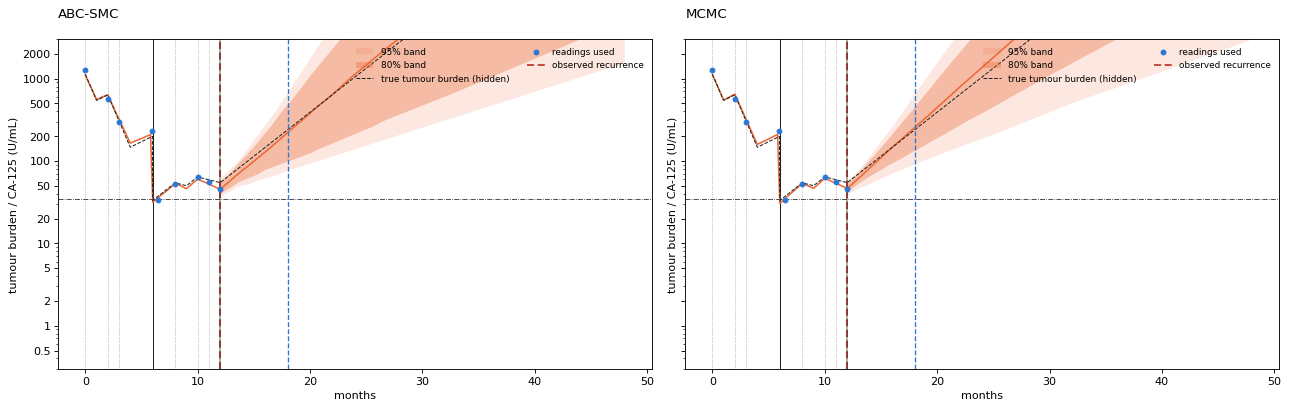

In [30]:
# The same Snapshot.plot API used in Section 2 draws each forecast.
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True, sharey=True,
                         constrained_layout=True)
snap.plot(ax=axes[0])
mcmc_snap.plot(ax=axes[1])
axes[0].set_title("ABC-SMC\n" + axes[0].get_title(), loc="left")
axes[1].set_title("MCMC\n" + axes[1].get_title(), loc="left")
plt.show()

# Save the comparison if desired:
# fig.savefig("abc_mcmc_comparison.png", dpi=140, bbox_inches="tight")
